# 02 · Survival analysis: time until a well's next failure

**Question:** after a well is (re)started, *how long until its rod string or pump fails again*, and *what makes some wells fail sooner*?

This is a predictive-maintenance problem, and survival analysis is the standard tool for it. The notebook goes from "describe" to "explain" to "predict" to "act":

| § | Step | Library | Answers |
|---|---|---|---|
| 1 | Build the survival dataset | pandas | what is one observation? |
| 2 | Kaplan–Meier and Nelson–Aalen | `lifelines` | what does the failure curve look like? |
| 3 | Log-rank tests | `lifelines` | do groups really differ? |
| 4 | Exponential vs Weibull | `lifelines` | early failures or wear-out? |
| 5 | Cox proportional hazards | `lifelines` | which factors multiply risk, and by how much? |
| 6 | Random Survival Forest and gradient boosting | `scikit-survival` | can ML predict better? (validated on 2025–26) |
| 7 | Risk ranking and expected cost | both | which wells should crews visit first? |
| 8 | SHAP explanations | `shap` | *why* is this well flagged? |
| 9 | Cox vs ML cross-check | both | can we trust the ML model? |

**Three-layer design:** scikit-survival **predicts**, SHAP **explains each alert**, and the lifelines Cox model gives the **fleet-level view** and a **cross-check** on the ML model.

---
### Why not ordinary regression or classification?

Let $T$ be the (random) time until failure. For most runs **we never see $T$**. The well is still running when the data ends, or it was shut in for other reasons. All we know is $T > c$, where $c$ is the time we watched it. That is called **right-censoring**.

- Dropping censored runs throws away the healthiest wells, so survival looks worse than it is.
- Treating censored runs as "failed at $c$" makes survival look worse as well.
- Treating them as "never fails" (as a classifier does) makes survival look better than it is.

Survival methods use each censored run correctly: *it survived at least $c$ days*.

### The four functions everything is built on

$$
\underbrace{S(t)=P(T>t)}_{\text{survival}}\qquad
\underbrace{f(t)=-S'(t)}_{\text{density}}\qquad
\underbrace{h(t)=\lim_{\Delta\to0}\frac{P(t\le T<t+\Delta\mid T\ge t)}{\Delta}=\frac{f(t)}{S(t)}}_{\text{hazard: instantaneous failure rate given still running}}\qquad
\underbrace{H(t)=\int_0^t h(u)\,du}_{\text{cumulative hazard}}
$$

and they are tied together by

$$S(t)=\exp\!\big(-H(t)\big).$$

The **hazard** is the most useful for maintenance. It answers "given this pump has survived $t$ days, how likely is it to fail *today*?"

## 0 · Setup

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "Competition Dataset").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from common import *          # paths, palette, hbar(), load()
apply_style()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

from lifelines import KaplanMeierFitter, NelsonAalenFitter, CoxPHFitter
from lifelines import ExponentialFitter, WeibullFitter, LogNormalFitter, LogLogisticFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test

from sksurv.util import Surv
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis
from sksurv.metrics import (concordance_index_censored, concordance_index_ipcw,
                            cumulative_dynamic_auc, integrated_brier_score)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

In [2]:
%%time
COLS = ["uwi", "production_date", "well_daily_status", "field_operating_area", "on_production_date",
        "oil_produced_m3", "water_produced_m3", "hours_on_prod", "hours_down", "lost_oil_m3",
        "pcp_pump_rpm", "pcp_pump_make", "pcp_pump_displacement_m3d100rpm", "pump_efficiency_pct",
        "pcp_pump_rod_torque_ftlb", "casing_pressure_kpa"]
dp = load("daily_production", columns=COLS)
fails = load("production_failures")
jobs = load("well_jobs")
print(f"{len(dp):,} well-days · {len(fails):,} failures · {len(jobs):,} jobs")

5,075,590 well-days · 2,873 failures · 15,610 jobs
CPU times: total: 5.17 s
Wall time: 1.4 s


## 1 · Building the survival dataset

### ⚠️ First, a data problem: the failure log only starts in April 2025

`production_failures` has just 2 records before Q2 2025, while rod-truck and workover jobs run at a steady ~2,500 a year from 2021. For 2021–24 the failures are **missing, not absent**. Treating the log as complete would make wells look perfectly reliable for three years.

**Fix:** use **failure-repair jobs** from `well_jobs` as the event. These are Rod Truck or Workover jobs whose `job_type` is a repair or replacement (rod, polish rod, pump, rotor, tubing, packer and so on), excluding planned work such as upgrades, clean-outs, acid jobs and suspensions. The overlap period (Apr 2025 →) lets us check the proxy, below.

Repair jobs as a failure proxy (Apr 2025 →): precision ≈ 79%, recall ≈ 95%


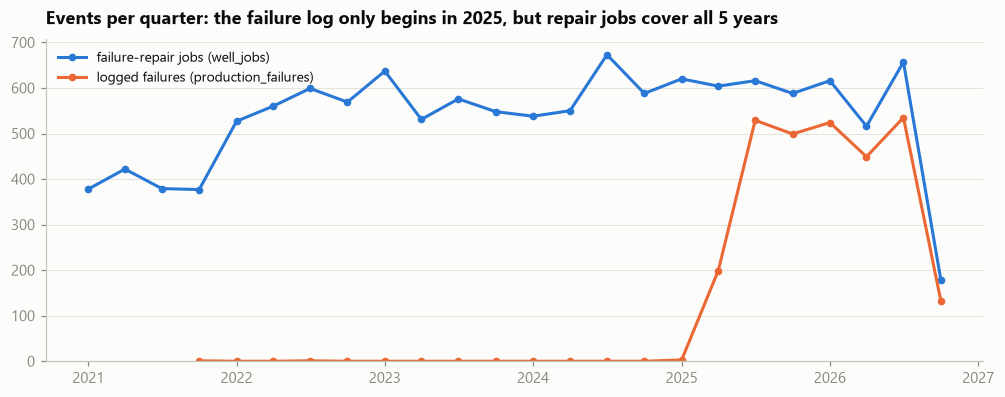

In [3]:
jobs["uwi"] = jobs.uwi.astype(str)
fails["uwi"] = fails.uwi.astype(str)
REPAIR = (jobs.job_category.astype(str).isin(["Rod Truck", "Workover"]) &
          jobs.job_type.astype(str).str.contains("Repair|Replacement|Break|Rotor", regex=True))
rep = jobs[REPAIR].copy()

# Precision of the proxy in the overlap period: does a repair job match a logged failure (−30…+3 days)?
ov = rep[(rep.start_date >= "2025-04-01") & (rep.start_date <= fails.failure_start_date.max())]
m = ov[["uwi", "start_date"]].reset_index(names="jid").merge(fails[["uwi", "failure_start_date"]], on="uwi")
precision = m[(m.start_date - m.failure_start_date).dt.days.between(-30, 3)].jid.nunique() / len(ov)
# Recall: does a logged failure get a repair job within (−3…+30 days)?
m2 = fails[["uwi", "failure_start_date"]].reset_index(names="fid").merge(rep[["uwi", "start_date"]], on="uwi")
recall = m2[(m2.start_date - m2.failure_start_date).dt.days.between(-3, 30)].fid.nunique() / len(fails)
print(f"Repair jobs as a failure proxy (Apr 2025 →): precision ≈ {precision:.0%}, recall ≈ {recall:.0%}")

qf = fails.set_index("failure_start_date").resample("QS").size()
qj = rep.set_index("start_date").resample("QS").size()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(qj.index, qj.values, color=BLUE, marker="o", ms=4, label="failure-repair jobs (well_jobs)")
ax.plot(qf.index, qf.values, color=ORANGE, marker="o", ms=4, label="logged failures (production_failures)")
ax.set_title("Events per quarter: the failure log only begins in 2025, but repair jobs cover all 5 years")
ax.legend(loc="upper left"); ax.set_ylim(bottom=0)
plt.show()

**One observation = one *run*.** A run starts when a well restarts after a repair and ends at its next repair (an event, $\delta=1$) or at the end of what we can see (censored, $\delta=0$). This is the **"gap time"** form of a *recurrent-event* model: the clock resets at every repair.

Design choices, each worth defending to judges:

| Choice | What we do | Why |
|---|---|---|
| **Event** | a failure-repair job (above) | the only failure record covering 2021–26 |
| **Clock** | count only days with `hours_on_prod > 0` | time spent shut in is not "surviving". Pumps wear only while they turn |
| **Origin** | runs must start *after a repair* | a well's first run in the window began at an unknown time before 2021 (*left truncation*), so its clock would be wrong |
| **Duplicate events** | merge repairs < 3 days apart on the same well | one breakdown, two tickets |
| **Landmark** | covariates are measured over the first 7 run-days, and the clock starts *after* them | prevents **leakage**: features may not contain the run-up to the failure we are predicting |
| **Censoring** | end of data, or the well stops producing | standard right-censoring (see limitations on informative censoring) |

In [4]:
WIN_START = dp.production_date.min()
DATA_END = dp.production_date.max()
LANDMARK = 7                                  # days of covariate measurement after each restart
CUT = pd.Timestamp("2025-01-01")              # train/test split for §6

def component(jt):
    jt = str(jt)
    if "Pump" in jt or "Rotor" in jt or "PCP" in jt: return "Pump"
    if "Tubing" in jt or "Packer" in jt: return "Tubing"
    if "Rod" in jt: return "Rods"
    return "Other"

# --- events: one row per distinct repair, numbered k = 0,1,2,... per well
f = rep.rename(columns={"start_date": "failure_start_date"})[["uwi", "failure_start_date", "job_type", "field_est_total"]]
f = f.assign(cause=f.job_type.map(component), failure_type=f.job_type.astype(str))
f = f.sort_values(["uwi", "failure_start_date"])
f = f[~(f.groupby("uwi").failure_start_date.diff().dt.days <= 3)].copy()
f["k"] = f.groupby("uwi").cumcount()

# --- run-days: days in the window on which the pump actually ran
prod = dp[(dp.production_date >= WIN_START) & (dp.hours_on_prod > 0)].copy()
prod["uwi"] = prod.uwi.astype(str)
prod = prod.drop_duplicates(["uwi", "production_date"]).sort_values("production_date")
for c in ["casing_pressure_kpa", "pcp_pump_rod_torque_ftlb"]:
    prod.loc[prod[c] >= 99_999, c] = np.nan

# Each day belongs to run k+1, where k is the last failure strictly *before* that day
prod = pd.merge_asof(prod, f[["uwi", "failure_start_date", "k"]].sort_values("failure_start_date")
                     .rename(columns={"failure_start_date": "prev_fail"}),
                     left_on="production_date", right_on="prev_fail", by="uwi",
                     direction="backward", allow_exact_matches=False)
prod["run_id"] = (prod.k + 1).fillna(0).astype(int)
prod = prod.drop(columns="k").sort_values(["uwi", "production_date"])
prod["day_in_run"] = prod.groupby(["uwi", "run_id"]).cumcount()
prod["pre_cut"] = prod.production_date < CUT
print(f"{len(prod):,} run-days on {prod.uwi.nunique():,} wells")

3,336,701 run-days on 2,194 wells


In [5]:
# --- one row per run: duration, event, and the failure that ended it
runs = (prod.groupby(["uwi", "run_id"])
        .agg(start=("production_date", "min"), end=("production_date", "max"),
             duration=("production_date", "size"), dur_pre_cut=("pre_cut", "sum"))
        .reset_index())
runs = runs.merge(f[["uwi", "k", "failure_start_date", "cause", "failure_type"]],
                  left_on=["uwi", "run_id"], right_on=["uwi", "k"], how="left").drop(columns="k")
runs["event"] = runs.failure_start_date.notna()

# --- covariates measured over the first LANDMARK run-days (no peeking at the run-up to failure)
early = (prod[prod.day_in_run < LANDMARK].groupby(["uwi", "run_id"])
         .agg(oil=("oil_produced_m3", "median"), water=("water_produced_m3", "median"),
              rpm=("pcp_pump_rpm", "median"), disp=("pcp_pump_displacement_m3d100rpm", "median"),
              eff=("pump_efficiency_pct", "median"), torque=("pcp_pump_rod_torque_ftlb", "median"),
              casing=("casing_pressure_kpa", "median"),
              make=("pcp_pump_make", "first"), area=("field_operating_area", "first"),
              onprod=("on_production_date", "first")))
runs = runs.merge(early.reset_index(), on=["uwi", "run_id"], how="left")

# --- history: what failed last time, and how many failures in the previous year
prev = f[["uwi", "k", "cause"]].rename(columns={"cause": "prev_cause"}).assign(run_id=lambda d: d.k + 1)
runs = runs.merge(prev[["uwi", "run_id", "prev_cause"]], on=["uwi", "run_id"], how="left")
tmp = runs[["uwi", "run_id", "start"]].merge(f[["uwi", "failure_start_date"]].rename(
    columns={"failure_start_date": "fd"}), on="uwi")
tmp = tmp[(tmp.fd < tmp.start) & (tmp.fd >= tmp.start - pd.Timedelta(days=365))]
runs = runs.merge(tmp.groupby(["uwi", "run_id"]).size().rename("fails_365").reset_index(),
                  on=["uwi", "run_id"], how="left")
runs["fails_365"] = runs.fails_365.fillna(0)

# --- tidy covariates
runs["water_cut"] = runs.water / (runs.water + runs.oil)
runs["age_yrs"] = (runs.start - runs.onprod).dt.days / 365.25
runs["prior_fails"] = runs.run_id
runs["prev_cause_grp"] = runs.prev_cause.fillna("None").astype(str)     # component repaired last time
runs["area"] = runs.area.astype(str)
runs["make"] = runs.make.astype(str).replace("nan", "Unknown")
TOP_AREAS = runs.area.value_counts().index[:6].tolist()
TOP_MAKES = [m for m in runs.make.value_counts().index if m != "Unknown"][:3]
runs["area_grp"] = runs.area.where(runs.area.isin(TOP_AREAS), "Other")
runs["make_grp"] = runs.make.where(runs.make.isin(TOP_MAKES), "Other/unknown")

# --- landmark: the clock starts after the 7-day measurement window
after = runs[runs.run_id >= 1]                    # runs with a known origin (started after a repair)
infant = after[after.duration <= LANDMARK]
S = after[after.duration > LANDMARK].copy().reset_index(drop=True)
S["T"] = S.duration - LANDMARK
S["E"] = S.event.astype(bool)

print(f"all runs: {len(runs):,} · first runs dropped (unknown origin): {(runs.run_id == 0).sum():,} · "
      f"runs after a repair: {len(after):,}")
print(f"repeat failures within the first {LANDMARK} run-days after a repair: {infant.event.sum():,} "
      f"({infant.event.sum()/after.event.sum():.1%} of failures) → infant mortality, excluded by the landmark")
print(f"analysis set: {len(S):,} runs on {S.uwi.nunique():,} wells, {S.E.sum():,} failures "
      f"({S.E.mean():.0%} of runs end in failure)")
S[["uwi", "run_id", "start", "end", "T", "E", "cause", "oil", "water_cut", "rpm", "area_grp", "prior_fails"]].head(8)

all runs: 13,307 · first runs dropped (unknown origin): 2,175 · runs after a repair: 11,132
repeat failures within the first 7 run-days after a repair: 911 (9.2% of failures) → infant mortality, excluded by the landmark
analysis set: 10,162 runs on 1,355 wells, 8,945 failures (88% of runs end in failure)


,uwi,run_id,start,end,T,E,cause,oil,water_cut,rpm,area_grp,prior_fails
0,100010503701W400,1,2023-01-09,2025-04-21,811,True,Pump,0.000000,1.000000,110.0,Other,1
1,100010503701W400,2,2025-05-11,2026-06-20,161,False,NaN,0.633276,0.936675,201.0,Other,2
2,100012403701W400,1,2024-05-19,2026-10-27,883,False,NaN,NaN,NaN,NaN,Bodo East,1
3,100013405817W400,1,2025-05-08,2025-05-15,1,True,Tubing,0.000000,NaN,NaN,Other,1
4,100013405817W400,2,2025-05-16,2026-10-27,515,False,NaN,7.400000,0.260000,120.0,Other,2
5,100013505817W400,1,2025-10-10,2026-08-09,296,True,Tubing,6.261600,0.403257,92.0,Other,1
6,100013505817W400,2,2026-08-22,2026-10-27,57,False,NaN,3.620394,0.565900,NaN,Other,2
7,100020205917W400,1,2022-08-30,2023-07-10,305,True,Rods,4.017608,0.553599,235.0,Other,1


**What censoring looks like.** Each line is one well. Each segment is a run on the calendar, ✕ marks a failure, and ○ marks a run still going (censored) when the data stops.

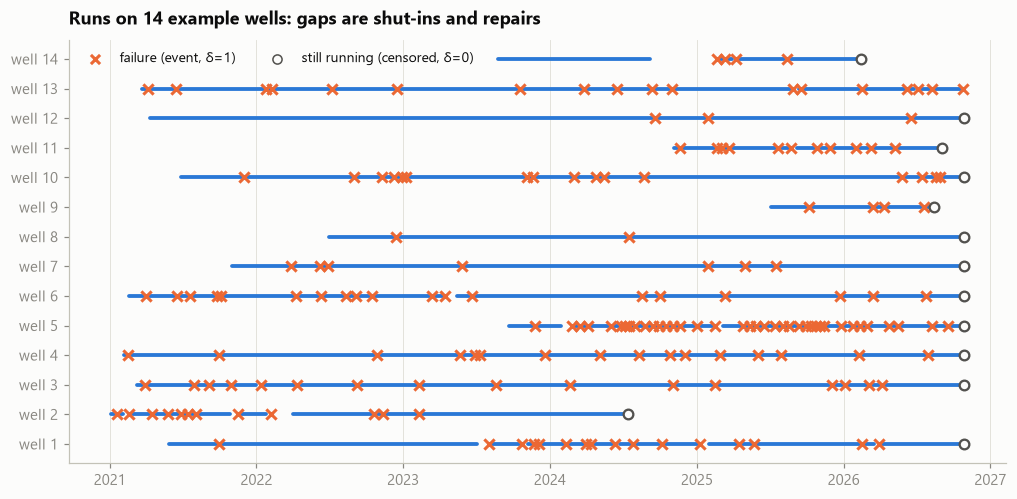

In [6]:
cand = S.groupby("uwi").agg(n=("run_id", "size"), ev=("E", "sum")).query("n >= 3 and ev >= 2")
pick = cand.sample(14, random_state=3).index
fig, ax = plt.subplots(figsize=(11, 5))
for i, w in enumerate(pick):
    r = S[S.uwi == w]
    for _, x in r.iterrows():
        ax.plot([x.start, x.end], [i, i], color=BLUE, lw=2.5, solid_capstyle="round")
        if x.E:
            ax.scatter(x.failure_start_date, i, marker="x", color=ORANGE, s=45, lw=2, zorder=3)
        else:
            ax.scatter(x.end, i, marker="o", facecolor=SURFACE, edgecolor=INK2, s=40, lw=1.5, zorder=3)
ax.set_yticks(range(len(pick)), [f"well {i+1}" for i in range(len(pick))])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.scatter([], [], marker="x", color=ORANGE, label="failure (event, δ=1)")
ax.scatter([], [], marker="o", facecolor=SURFACE, edgecolor=INK2, label="still running (censored, δ=0)")
ax.legend(loc="upper left", ncols=2)
ax.set_title("Runs on 14 example wells: gaps are shut-ins and repairs")
plt.show()

## 2 · Kaplan–Meier: the survival curve with no assumptions

Order the distinct failure times $t_1<t_2<\dots$. At each $t_i$ let $n_i$ be the number of runs still **at risk** (not yet failed or censored) and $d_i$ the number that fail. The **Kaplan–Meier (product-limit) estimator** is

$$\hat S(t)=\prod_{t_i\le t}\left(1-\frac{d_i}{n_i}\right).$$

Read it as "survive step 1, *and then* step 2, *and then*…". Censored runs leave the risk set $n_i$ without ever counting as a failure, which is how censoring is handled correctly. The confidence band comes from **Greenwood's formula**:

$$\widehat{\mathrm{Var}}\big[\hat S(t)\big]=\hat S(t)^2\sum_{t_i\le t}\frac{d_i}{n_i(n_i-d_i)}.$$

`lifelines`: `KaplanMeierFitter().fit(durations, event_observed)`.

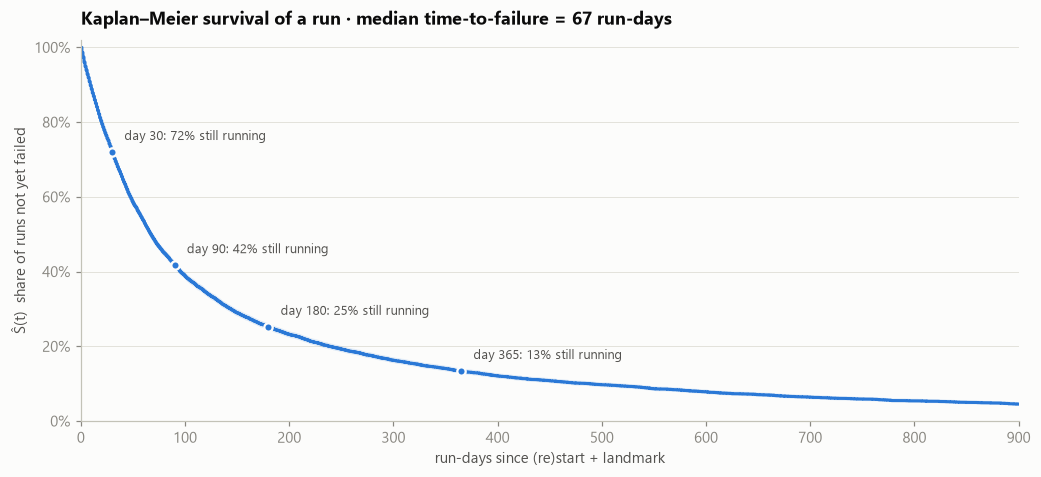

In [7]:
kmf = KaplanMeierFitter().fit(S["T"], S["E"], label="all runs")
sf, ci = kmf.survival_function_.iloc[:, 0], kmf.confidence_interval_

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step="post", color=BLUE, alpha=0.15, lw=0)
ax.step(sf.index, sf.values, where="post", color=BLUE)
for t in [30, 90, 180, 365]:
    s = kmf.predict(t)
    ax.scatter(t, s, color=BLUE, s=30, zorder=3, edgecolor=SURFACE, lw=1.5)
    ax.annotate(f"day {t}: {s:.0%} still running", (t, s), xytext=(8, 8), textcoords="offset points",
                fontsize=8.5, color=INK2)
ax.set_xlim(0, 900); ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("run-days since (re)start + landmark"); ax.set_ylabel("Ŝ(t)  share of runs not yet failed")
ax.set_title(f"Kaplan–Meier survival of a run · median time-to-failure = {kmf.median_survival_time_:,.0f} run-days")
plt.show()

### Nelson–Aalen: looking at the *hazard* directly

The **Nelson–Aalen** estimator of the cumulative hazard is $\hat H(t)=\sum_{t_i\le t} d_i/n_i$. Its slope is the hazard $h(t)$. Smoothing those jumps with a kernel of bandwidth $b$ gives an estimate of $h(t)$ itself, and **the shape of $h(t)$ is the maintenance story**:

- falling hazard → failures cluster soon after a restart (early failures)
- flat hazard → random failures
- rising hazard → wear-out

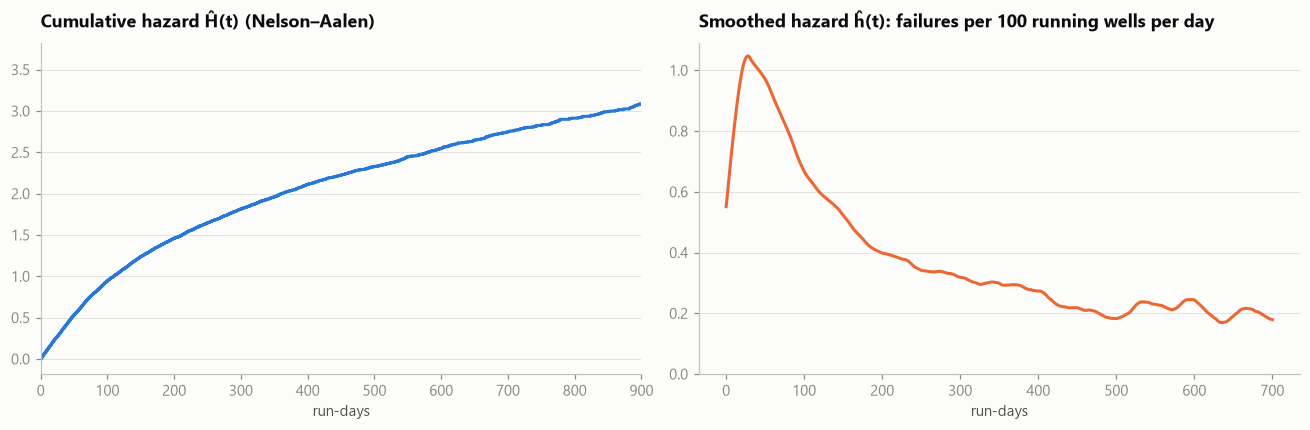

In [8]:
naf = NelsonAalenFitter().fit(S["T"], S["E"])
haz = naf.smoothed_hazard_(bandwidth=30).iloc[:, 0]
haz = haz[haz.index <= 700]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.step(naf.cumulative_hazard_.index, naf.cumulative_hazard_.iloc[:, 0], where="post", color=BLUE)
ax1.set_xlim(0, 900); ax1.set_title("Cumulative hazard Ĥ(t) (Nelson–Aalen)"); ax1.set_xlabel("run-days")
ax2.plot(haz.index, haz.values * 100, color=ORANGE)
ax2.set_title("Smoothed hazard ĥ(t): failures per 100 running wells per day"); ax2.set_xlabel("run-days")
ax2.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

## 3 · Comparing groups: the log-rank test

Is the difference between two Kaplan–Meier curves real or noise? At each failure time, if the groups had the **same** hazard, group $g$ would be *expected* to have $E_{gi}=d_i\cdot n_{gi}/n_i$ of the $d_i$ failures. The log-rank statistic adds up observed minus expected over all failure times:

$$\chi^2=\big(\mathbf O-\mathbf E\big)^{\!\top}\,\mathbf V^{-1}\big(\mathbf O-\mathbf E\big)\;\sim\;\chi^2_{G-1}\ \text{ under } H_0:\ h_1(t)=\dots=h_G(t).$$

`lifelines`: `multivariate_logrank_test(durations, groups, events)`.

> With thousands of runs almost any difference is "significant". Judge the **size** of the gap between curves (e.g. the medians), not just $p$.

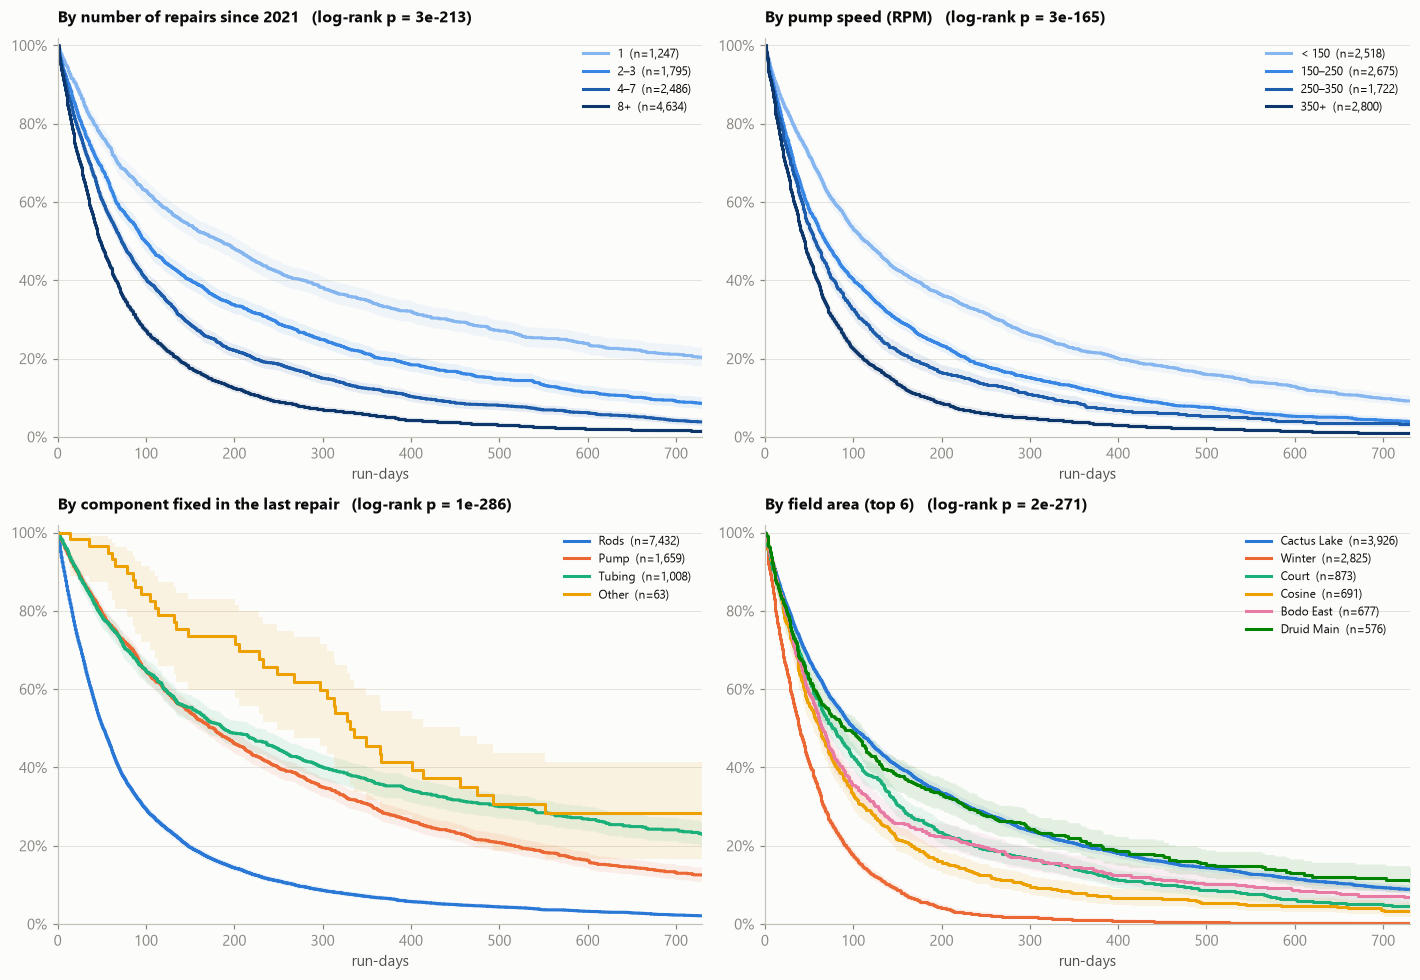

,prior_grp,runs,failures,median run-days,S(90),S(365),rpm_grp,prev_cause_grp,area_grp
0,1,1247,992,185,65%,34%,–,–,–
1,2–3,1795,1563,99,53%,20%,–,–,–
2,4–7,2486,2225,72,43%,12%,–,–,–
3,8+,4634,4165,48,30%,5%,–,–,–
4,–,2518,2086,114,56%,22%,< 150,–,–
5,–,2675,2424,69,43%,12%,150–250,–,–
6,–,1722,1575,57,35%,8%,250–350,–,–
7,–,2800,2633,44,25%,4%,350+,–,–
8,–,7432,6871,52,32%,7%,–,Rods,–
9,–,1659,1329,177,68%,29%,–,Pump,–


In [9]:
def km_by(ax, df, col, order, colors, title, tmax=730):
    rows = []
    for g, c in zip(order, colors):
        d = df[df[col] == g]
        if len(d) < 30:
            continue
        km = KaplanMeierFitter().fit(d["T"], d["E"])
        s, band = km.survival_function_.iloc[:, 0], km.confidence_interval_
        ax.fill_between(band.index, band.iloc[:, 0], band.iloc[:, 1], step="post", color=c, alpha=0.10, lw=0)
        ax.step(s.index, s.values, where="post", color=c, label=f"{g}  (n={len(d):,})")
        rows.append({col: g, "runs": len(d), "failures": int(d.E.sum()),
                     "median run-days": km.median_survival_time_, "S(90)": km.predict(90), "S(365)": km.predict(365)})
    sub = df[df[col].isin([r[col] for r in rows])]
    p = multivariate_logrank_test(sub["T"], sub[col], sub["E"]).p_value
    ax.set_xlim(0, tmax); ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(pct)
    ax.set_title(f"{title}   (log-rank p = {p:.1g})", fontsize=10.5)
    ax.set_xlabel("run-days"); ax.legend(loc="upper right", fontsize=8)
    return pd.DataFrame(rows)

S["prior_grp"] = pd.cut(S.prior_fails, [0, 1, 3, 7, 999], labels=["1", "2–3", "4–7", "8+"]).astype(str)
S["rpm_grp"] = pd.cut(S.rpm, [0, 150, 250, 350, 1e4], labels=["< 150", "150–250", "250–350", "350+"]).astype(str)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
tabs = [
    km_by(axes[0, 0], S, "prior_grp", ["1", "2–3", "4–7", "8+"], ORDINAL, "By number of repairs since 2021"),
    km_by(axes[0, 1], S, "rpm_grp", ["< 150", "150–250", "250–350", "350+"], ORDINAL, "By pump speed (RPM)"),
    km_by(axes[1, 0], S, "prev_cause_grp", ["Rods", "Pump", "Tubing", "Other"], SERIES, "By component fixed in the last repair"),
    km_by(axes[1, 1], S, "area_grp", TOP_AREAS, SERIES, "By field area (top 6)"),
]
plt.tight_layout(); plt.show()
pd.concat(tabs, ignore_index=True).style.format({"median run-days": "{:,.0f}", "S(90)": "{:.0%}", "S(365)": "{:.0%}"}, na_rep="–")

## 4 · Parametric models: is the hazard constant, falling or rising?

A parametric model assumes $T$ follows a named distribution. That gives a smooth curve and **one interpretable shape number**.

**Exponential**: constant hazard, *memoryless*:
$$h(t)=\lambda,\qquad S(t)=e^{-\lambda t},\qquad E[T]=1/\lambda.$$
Memoryless means $P(T>s+t\mid T>s)=P(T>t)$: a pump that has run 400 days is "as good as new". That is physically suspicious for fatigue.

**Weibull**: adds a shape parameter $\rho$ (often written $k$). In `lifelines`' parameterisation:
$$S(t)=\exp\!\Big[-\Big(\tfrac{t}{\lambda}\Big)^{\rho}\Big],\qquad h(t)=\frac{\rho}{\lambda}\Big(\frac{t}{\lambda}\Big)^{\rho-1}.$$

| $\rho$ | hazard | maintenance implication |
|---|---|---|
| $<1$ | falling | **early failures**: failures follow restarts, so fix *repair quality*. Scheduled replacement would add risk |
| $=1$ | constant | exponential: random failures, so scheduling replacement does nothing |
| $>1$ | rising | **wear-out**: preventive replacement before failure pays off |

Parameters are found by **maximum likelihood with censoring**. Failed runs contribute their density and censored runs their survival probability:
$$\log L(\theta)=\sum_i\Big[\delta_i\log f(t_i;\theta)+(1-\delta_i)\log S(t_i;\theta)\Big].$$
Models are compared with $\mathrm{AIC}=2p-2\log L$, where lower is better.

Weibull: λ (scale) = 138 run-days,  ρ (shape) = 0.713  [95% CI 0.702 – 0.724]

AIC (lower is better):
Log-logistic        +0
Log-normal         +54
Weibull         +1,000
Exponential     +3,179


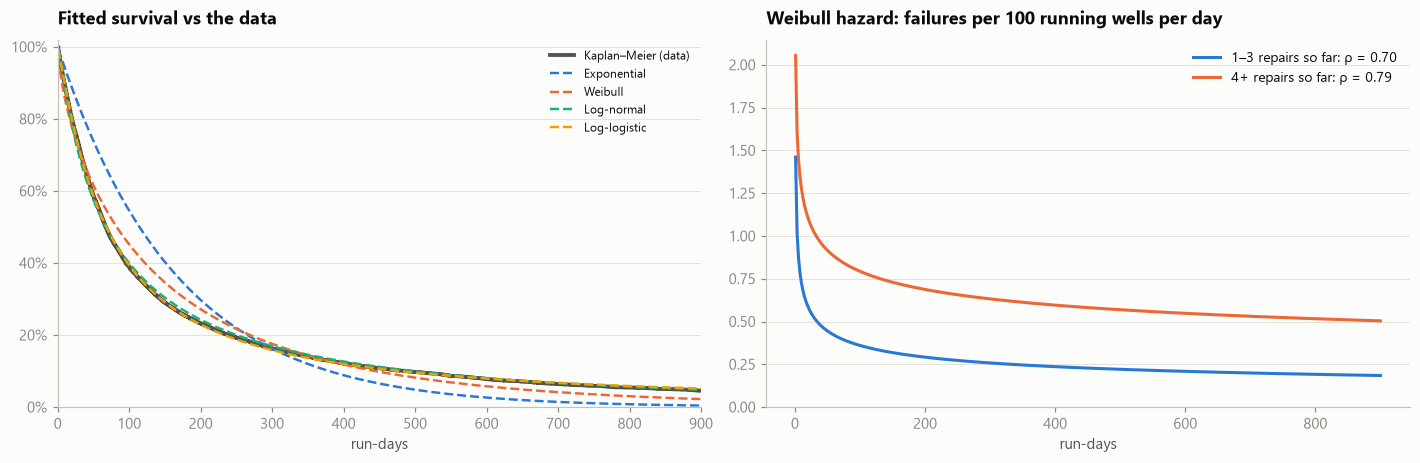

In [10]:
fitters = {"Exponential": ExponentialFitter(), "Weibull": WeibullFitter(),
           "Log-normal": LogNormalFitter(), "Log-logistic": LogLogisticFitter()}
for name, m in fitters.items():
    m.fit(S["T"], S["E"], label=name)
aic = pd.Series({n: m.AIC_ for n, m in fitters.items()}).sort_values()
wb = fitters["Weibull"]
rho_ci = wb.summary.loc["rho_", ["coef lower 95%", "coef upper 95%"]]
print(f"Weibull: λ (scale) = {wb.lambda_:,.0f} run-days,  ρ (shape) = {wb.rho_:.3f}  "
      f"[95% CI {rho_ci.iloc[0]:.3f} – {rho_ci.iloc[1]:.3f}]")
print("\nAIC (lower is better):\n" + (aic - aic.min()).map(lambda v: f"+{v:,.0f}").to_string())

t = np.linspace(1, 900, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.step(sf.index, sf.values, where="post", color=INK2, lw=2.5, label="Kaplan–Meier (data)")
for (name, m), c in zip(fitters.items(), SERIES):
    ax1.plot(t, m.survival_function_at_times(t), color=c, lw=1.6, ls="--", label=name)
ax1.set_xlim(0, 900); ax1.set_ylim(0, 1.02); ax1.yaxis.set_major_formatter(pct)
ax1.set_title("Fitted survival vs the data"); ax1.set_xlabel("run-days"); ax1.legend(fontsize=8)

for (lab, mask), c in zip([("1–3 repairs so far", S.prior_fails <= 3), ("4+ repairs so far", S.prior_fails >= 4)], [BLUE, ORANGE]):
    w = WeibullFitter().fit(S.loc[mask, "T"], S.loc[mask, "E"])
    ax2.plot(t, w.hazard_at_times(t) * 100, color=c, label=f"{lab}: ρ = {w.rho_:.2f}")
ax2.set_title("Weibull hazard: failures per 100 running wells per day"); ax2.set_xlabel("run-days")
ax2.set_ylim(bottom=0); ax2.legend()
plt.tight_layout(); plt.show()

## 5 · Cox proportional hazards: *which* factors drive failure

Kaplan–Meier compares one factor at a time. The **Cox model** handles many at once without assuming any distribution for the baseline:

$$h(t\mid \mathbf x)=\underbrace{h_0(t)}_{\text{baseline, any shape}}\cdot\exp\big(\beta_1x_1+\dots+\beta_px_p\big).$$

- $e^{\beta_j}$ is the **hazard ratio (HR)**: raising $x_j$ by one unit *multiplies* the failure rate by $e^{\beta_j}$ at every $t$. HR 1.30 means 30% more failures, and HR 0.80 means 20% fewer.
- $h_0(t)$ cancels out of the **partial likelihood**, so the $\beta$s are estimated without ever specifying it. At each failure time we ask "of all the runs still at risk, how likely was it *this* one that failed?":
$$L(\boldsymbol\beta)=\prod_{i:\,\delta_i=1}\frac{\exp(\mathbf x_i^{\top}\boldsymbol\beta)}{\sum_{j\in R(t_i)}\exp(\mathbf x_j^{\top}\boldsymbol\beta)},\qquad R(t_i)=\{j: t_j\ge t_i\}.$$
- **Repeated runs on the same well are not independent.** `cluster_col="uwi"` gives *robust (sandwich) standard errors* that allow for that (Lin–Wei).
- A small **ridge penalty** $\tfrac{\lambda}{2}\lVert\boldsymbol\beta\rVert^2$ keeps estimates stable when features are correlated.

Covariate units are chosen so the HRs read naturally: per +100 RPM, per +10 percentage points of water cut, per extra prior failure, and so on.

In [11]:
NUMERIC = ["log_oil", "water_cut_10pp", "rpm_100", "disp_100", "efficiency", "torque_1000",
           "age_10y", "prior_fails", "fails_last_365"]

def design(d, med=None, cols=None):
    """Numeric design matrix shared by lifelines and scikit-survival. Medians/columns come from TRAIN."""
    X = pd.DataFrame(index=d.index)
    X["log_oil"] = np.log1p(d.oil.clip(lower=0))
    X["water_cut_10pp"] = d.water_cut * 10
    X["rpm_100"] = d.rpm / 100
    X["disp_100"] = d.disp / 100
    X["efficiency"] = d.eff.clip(0, 2)
    X["torque_1000"] = d.torque.clip(0, 6000) / 1000
    X["age_10y"] = d.age_yrs.clip(0, 75) / 10
    X["prior_fails"] = d.prior_fails.clip(upper=10)
    X["fails_last_365"] = d.fails_365.clip(upper=10)
    if med is None:
        med = X.median()
    for c in NUMERIC:
        X[c + "_missing"] = X[c].isna().astype(float)
        X[c] = X[c].fillna(med[c])
    for v in ["Pump", "Tubing", "Other"]:                      # reference = last repair was rods
        X[f"last_repair_{v.lower()}"] = (d.prev_cause_grp == v).astype(float)
    for a in TOP_AREAS:
        X["area_" + a.replace(" ", "_")] = (d.area_grp == a).astype(float)
    for m in TOP_MAKES:
        X["make_" + m.replace(" ", "_")] = (d.make_grp == m).astype(float)
    if cols is None:
        cols = [c for c in X.columns if X[c].std() > 0]
    return X[cols].astype(float), med, cols

X_all, MED_ALL, COLS_ALL = design(S)
cox_df = X_all.assign(T=S["T"], E=S["E"].astype(int), uwi=S["uwi"])
cph = CoxPHFitter(penalizer=0.01).fit(cox_df, "T", "E", cluster_col="uwi")
print(f"Concordance (in-sample) = {cph.concordance_index_:.3f}   ·   {len(cox_df):,} runs, {int(cox_df.E.sum()):,} failures")
summ = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
summ.rename(columns={"exp(coef)": "HR", "exp(coef) lower 95%": "HR low", "exp(coef) upper 95%": "HR high"}) \
    .sort_values("HR", ascending=False).style.format("{:.3f}").format({"p": "{:.1g}"})

Concordance (in-sample) = 0.671   ·   10,162 runs, 8,945 failures


,HR,HR low,HR high,p
covariate,,,,
area_Winter,1.593704,1.414311,1.795852,2e-14
log_oil,1.201594,1.152188,1.253118,1e-17
area_Court,1.195384,1.060858,1.346970,0.003
disp_100_missing,1.179690,0.863933,1.610851,0.3
fails_last_365,1.090592,1.075587,1.105806,1e-34
area_Cosine,1.087661,0.951287,1.243585,0.2
rpm_100,1.069709,1.039702,1.100583,3e-06
area_Cactus_Lake,1.057728,0.946166,1.182446,0.3
make_PCM,1.052634,0.987747,1.121784,0.1


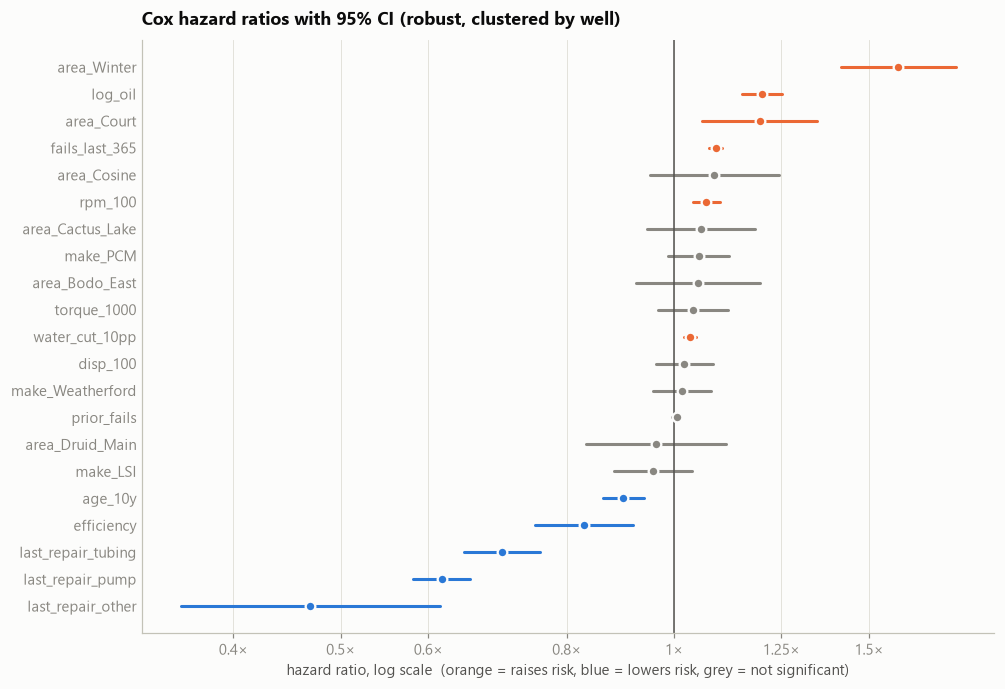

In [12]:
show = summ[~summ.index.str.endswith("_missing")].sort_values("exp(coef)")
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(show))
sig = show.p < 0.05
for yi, (name, r), s in zip(y, show.iterrows(), sig):
    c = (ORANGE if r["exp(coef)"] > 1 else BLUE) if s else MUTED
    ax.plot([r["exp(coef) lower 95%"], r["exp(coef) upper 95%"]], [yi, yi], color=c, lw=2, solid_capstyle="round")
    ax.scatter(r["exp(coef)"], yi, color=c, s=40, zorder=3, edgecolor=SURFACE, lw=1.5)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_locator(mtick.FixedLocator([0.4, 0.5, 0.6, 0.8, 1, 1.25, 1.5, 2]))
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set_yticks(y, show.index); ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Cox hazard ratios with 95% CI (robust, clustered by well)")
ax.set_xlabel("hazard ratio, log scale  (orange = raises risk, blue = lowers risk, grey = not significant)")
plt.show()

### Checking the proportional-hazards assumption

Cox assumes each HR is **constant over time**. The test correlates the *scaled Schoenfeld residuals* of each covariate with time. A small $p$ means that covariate's effect drifts with run age. With this many runs, small $p$ values are common. Fixes include stratifying on that variable (`strata=[...]`) or interacting it with time. The scikit-survival models in §6 don't need the assumption at all.

In [13]:
ph = proportional_hazard_test(cph, cox_df, time_transform="rank")
ph.summary[["test_statistic", "p"]].sort_values("p").head(10).style.format({"test_statistic": "{:.1f}", "p": "{:.1g}"})

,test_statistic,p
last_repair_pump,49.0,3e-12
last_repair_tubing,20.5,6e-06
fails_last_365,11.2,0.0008
last_repair_other,9.0,0.003
area_Winter,6.8,0.009
rpm_100,5.4,0.02
prior_fails,4.8,0.03
area_Cactus_Lake,4.6,0.03
area_Druid_Main,4.2,0.04
disp_100,3.6,0.06


## 6 · Machine learning with scikit-survival, validated on the future

**Honest validation is a time split.** Train on what was known before 1 Jan 2025 and test on runs that *start* in 2025–26. Training runs still going on the cut date are censored there, so the model never sees the future.

**Models**

- **Cox (sksurv)**: the same model as §5, used here as the interpretable benchmark.
- **Random Survival Forest (RSF)**: each tree splits on the feature and threshold that **maximise the log-rank statistic** between the two child nodes. Each leaf stores a Nelson–Aalen cumulative hazard, and the forest averages them: $\hat H(t\mid\mathbf x)=\frac1B\sum_b \hat H_b(t\mid\mathbf x)$. It captures non-linear effects and interactions with no proportional-hazards assumption.
- **Gradient-boosted Cox (GBSA)**: builds $f(\mathbf x)=\sum_m \nu\,g_m(\mathbf x)$ from small trees by gradient descent on the negative Cox partial log-likelihood.
- **Baseline**: Cox using only failure history (`prior_fails`, `fails_last_365`). Any model has to beat this to be worth having.

`scikit-survival` wants the target as a structured array: `y = Surv.from_arrays(event, time)`.

**Metrics**

| Metric | Formula / idea | Good |
|---|---|---|
| Harrell's C | $P(\hat r_i>\hat r_j\mid T_i<T_j)$ over comparable pairs: does the riskier-scored run fail first? | 0.5 = random, 1 = perfect |
| Uno's C (IPCW) | the same, with pairs weighted by $1/\hat G(T_i)^2$, where $\hat G$ is the KM curve of the *censoring* times. Removes censoring bias; truncated at $\tau$ = 365 d | ↑ |
| Time-dependent AUC $(t)$ | separates runs failing **by** $t$ from runs surviving **past** $t$: $P(\hat r_i>\hat r_j\mid T_i\le t<T_j)$ | ↑ |
| Integrated Brier score | $\frac1{t_{\max}}\int \frac1n\sum_i w_i(t)\big(\mathbb 1\{T_i>t\}-\hat S(t\mid\mathbf x_i)\big)^2dt$: accuracy of the *probabilities* (calibration) | ↓ (0.25 ≈ coin-flip) |

In [14]:
tr = S[S.start < CUT].copy()
tr["T"] = tr.dur_pre_cut - LANDMARK
tr["E"] = tr.E & (tr.failure_start_date < CUT)
tr = tr[tr["T"] > 0]
te = S[S.start >= CUT].copy()

X_tr, MED, COLS = design(tr)
X_te, _, _ = design(te, MED, COLS)
y_tr = Surv.from_arrays(tr.E.to_numpy(bool), tr["T"].to_numpy(float))
y_te = Surv.from_arrays(te.E.to_numpy(bool), te["T"].to_numpy(float))
print(f"train: {len(tr):,} runs ({tr.E.sum():,} failures) · test: {len(te):,} runs ({te.E.sum():,} failures) · {X_tr.shape[1]} features")

HIST = ["prior_fails", "fails_last_365"]
models = {
    "Baseline (history only)": (CoxPHSurvivalAnalysis(alpha=0.01), HIST),
    "Cox (all features)": (CoxPHSurvivalAnalysis(alpha=0.01), COLS),
    "Random survival forest": (RandomSurvivalForest(n_estimators=300, min_samples_leaf=25, max_features="sqrt",
                                                    n_jobs=-1, random_state=0), COLS),
    "Gradient-boosted Cox": (GradientBoostingSurvivalAnalysis(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                              subsample=0.8, random_state=0), COLS),
}
for name, (m, cols) in models.items():
    m.fit(X_tr[cols], y_tr)

train: 6,665 runs (5,653 failures) · test: 3,464 runs (2,599 failures) · 28 features


,Harrell C,Uno C (τ=365),mean AUC(30–360d),IBS
model,,,,
Baseline (history only),0.632,0.632,0.688,0.139
Cox (all features),0.673,0.672,0.741,0.125
Random survival forest,0.674,0.674,0.745,0.123
Gradient-boosted Cox,0.678,0.677,0.748,0.122


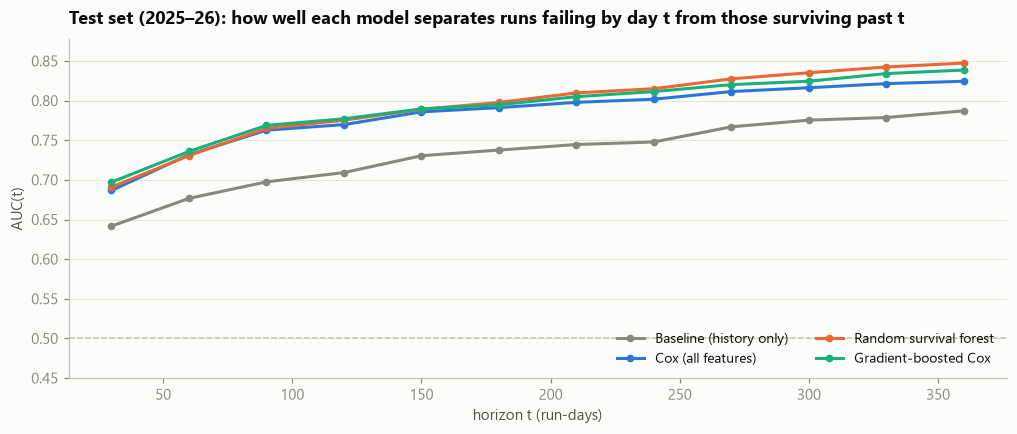

In [15]:
times = np.arange(30, 361, 30)
times = times[times < te["T"].max()]
res, auc_curves, risk_te = [], {}, {}
for name, (m, cols) in models.items():
    r = m.predict(X_te[cols])                       # risk score: higher = fails sooner
    risk_te[name] = r
    surv = np.vstack([fn(times) for fn in m.predict_survival_function(X_te[cols])])
    auc_t, auc_mean = cumulative_dynamic_auc(y_tr, y_te, r, times)
    auc_curves[name] = auc_t
    res.append({"model": name,
                "Harrell C": concordance_index_censored(y_te["event"], y_te["time"], r)[0],
                "Uno C (τ=365)": concordance_index_ipcw(y_tr, y_te, r, tau=365)[0],
                "mean AUC(30–360d)": auc_mean,
                "IBS": integrated_brier_score(y_tr, y_te, surv, times)})
results = pd.DataFrame(res).set_index("model")
display(results.style.format("{:.3f}").highlight_max(subset=["Harrell C", "Uno C (τ=365)", "mean AUC(30–360d)"],
                                                    color="#cde2fb").highlight_min(subset=["IBS"], color="#cde2fb"))

fig, ax = plt.subplots(figsize=(11, 4))
for (name, a), c in zip(auc_curves.items(), [MUTED, BLUE, ORANGE, AQUA]):
    ax.plot(times, a, color=c, marker="o", ms=4, label=name)
ax.axhline(0.5, color=AXIS, lw=1, ls="--")
ax.set_ylim(0.45, max(0.8, max(max(a) for a in auc_curves.values()) + 0.03))
ax.set_xlabel("horizon t (run-days)"); ax.set_ylabel("AUC(t)")
ax.set_title("Test set (2025–26): how well each model separates runs failing by day t from those surviving past t")
ax.legend(loc="lower right", ncols=2)
plt.show()

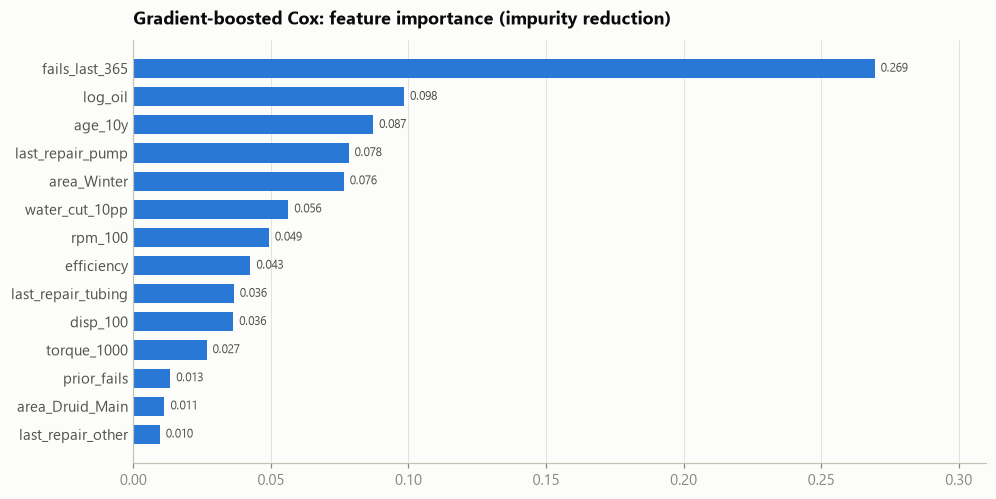

In [16]:
gb = models["Gradient-boosted Cox"][0]
imp = pd.Series(gb.feature_importances_, index=COLS)
imp = imp[~imp.index.str.endswith("_missing")].nlargest(14)
fig, ax = plt.subplots(figsize=(10, 5))
hbar(ax, imp, fmt="{:.3f}", title="Gradient-boosted Cox: feature importance (impurity reduction)")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.2f}"))
plt.show()

## 7 · Putting it to work: which wells should crews visit first?

A risk score is only useful if it changes a decision. Two steps:

**(a) Does ranking by risk actually catch failures?** On the 2025–26 test runs: if crews could proactively visit only the top $x\%$ of runs by predicted risk, what share of the failures that happened within 90 days would they have reached? A random choice catches $x\%$.

**(b) Expected cost of the next failure for every well running today.** For a well that has already run $t_0$ days, the probability it fails in the next 90 days is **conditional** on having survived so far:

$$P(T\le t_0+90\mid T>t_0)=1-\frac{\hat S(t_0+90\mid\mathbf x)}{\hat S(t_0\mid\mathbf x)}.$$

Multiply by what a failure costs (lost oil while down, plus the repair job) to get an **expected 90-day loss** per well. Sort by that, and you have the crew's work list.

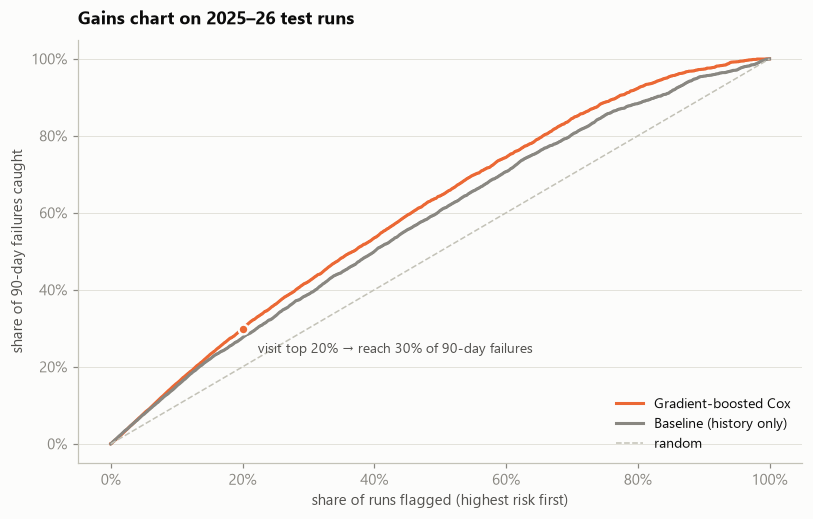

In [17]:
best = results["Uno C (τ=365)"].idxmax()
H = 90
ok = te.E.to_numpy() | (te["T"].to_numpy() >= H)                 # outcome at 90 d is known
fail90 = (te.E.to_numpy() & (te["T"].to_numpy() <= H))[ok]

fig, ax = plt.subplots(figsize=(8.5, 5))
for name, c in [(best, ORANGE), ("Baseline (history only)", MUTED)]:
    order = np.argsort(-risk_te[name][ok])
    cap = np.concatenate([[0], np.cumsum(fail90[order]) / fail90.sum()])
    x = np.linspace(0, 1, len(cap))
    ax.plot(x, cap, color=c, label=name)
    if name == best:
        k = int(0.2 * len(order))
        ax.scatter(0.2, cap[k], color=c, s=40, zorder=3, edgecolor=SURFACE, lw=1.5)
        ax.annotate(f"visit top 20% → reach {cap[k]:.0%} of 90-day failures", (0.2, cap[k]),
                    xytext=(10, -16), textcoords="offset points", fontsize=9, color=INK2)
ax.plot([0, 1], [0, 1], color=AXIS, ls="--", lw=1, label="random")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("share of runs flagged (highest risk first)"); ax.set_ylabel("share of 90-day failures caught")
ax.set_title("Gains chart on 2025–26 test runs"); ax.legend(loc="lower right")
plt.show()

In [18]:
# ---- Cost assumptions (edit these; they are deliberately simple and visible)
PRICE_CAD_PER_BBL = 60.0           # ASSUMPTION: realised heavy-oil netback, CAD/bbl
BBL_PER_M3 = 6.29

# Downtime per failure: well-days down in the 21 days after a failure, from the daily data
fd = f[["uwi", "failure_start_date"]].merge(dp[["uwi", "production_date", "hours_down"]]
                                            .assign(uwi=lambda d: d.uwi.astype(str)), on="uwi")
fd = fd[(fd.production_date >= fd.failure_start_date) &
        (fd.production_date < fd.failure_start_date + pd.Timedelta(days=21))]
DOWN_DAYS = (fd.groupby(["uwi", "failure_start_date"]).hours_down.sum() / 24).median()

# Repair cost: mean field-estimated cost of a failure-repair job
REPAIR_COST = f.field_est_total.mean()
print(f"median downtime per failure ≈ {DOWN_DAYS:.1f} well-days · mean repair cost ≈ ${REPAIR_COST:,.0f}")

# ---- Refit the best model on ALL runs, then score every run still going at the end of the data
final, fcols = models[best]
final = type(final)(**final.get_params()).fit(X_all[fcols], Surv.from_arrays(S.E.to_numpy(bool), S["T"].to_numpy(float)))
active = S[(~S.E) & (S.end >= DATA_END - pd.Timedelta(days=7))].copy()
fns = final.predict_survival_function(X_all.loc[active.index, fcols])
t0 = active["T"].to_numpy(float)
p90 = []
for fn, t in zip(fns, t0):
    lo, hi = fn.domain
    a, b = np.clip(t, lo, hi), np.clip(t + H, lo, hi)
    p90.append(1 - fn(b) / max(fn(a), 1e-9))
active["p_fail_90d"] = p90

recent = prod[prod.production_date >= DATA_END - pd.Timedelta(days=30)].groupby("uwi").oil_produced_m3.median()
active["oil_rate_m3d"] = active.uwi.map(recent).fillna(0)
active["exp_cost_90d"] = active.p_fail_90d * (active.oil_rate_m3d * DOWN_DAYS * BBL_PER_M3 * PRICE_CAD_PER_BBL + REPAIR_COST)
active = active.sort_values("exp_cost_90d", ascending=False)

tot = active.exp_cost_90d.sum()
top10 = active.exp_cost_90d.head(int(0.1 * len(active))).sum()
print(f"{len(active):,} wells running today · expected failures next 90 d ≈ {active.p_fail_90d.sum():,.0f} · "
      f"expected cost ≈ ${tot/1e6:,.1f}M · top 10% of wells carry {top10/tot:.0%} of it")

median downtime per failure ≈ 1.6 well-days · mean repair cost ≈ $12,463


1,020 wells running today · expected failures next 90 d ≈ 314 · expected cost ≈ $4.6M · top 10% of wells carry 26% of it


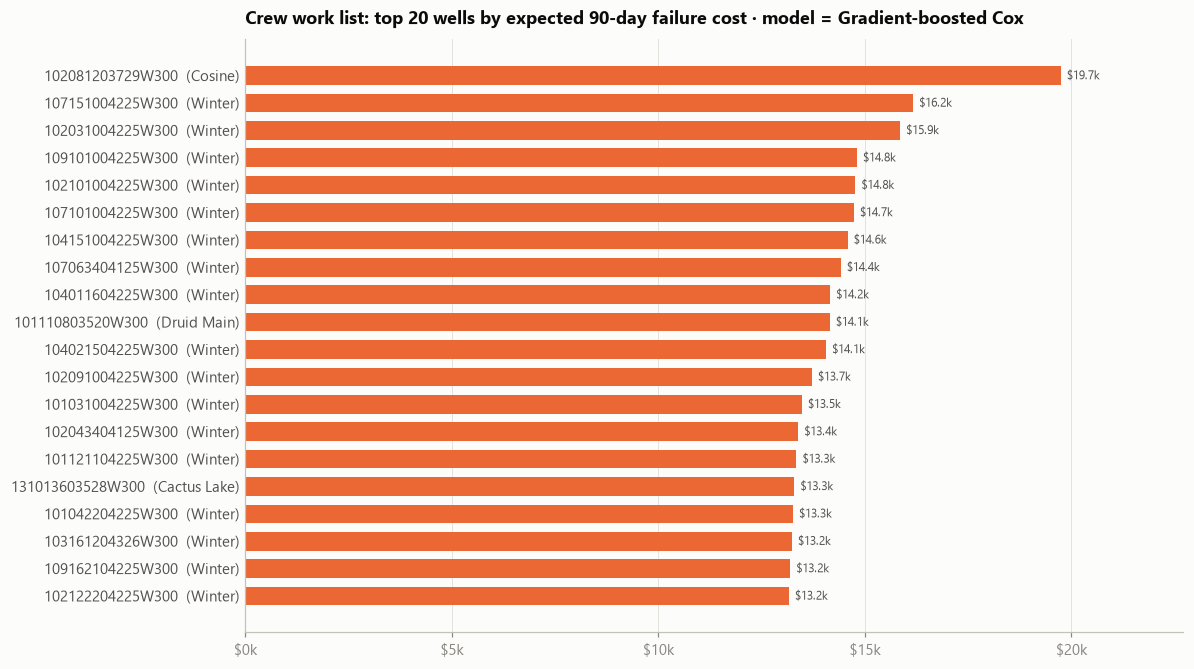

uwi,area,p_fail_90d,oil_rate_m3d,prior_fails,fails_365,rpm,days_running,exp_cost_90d
102081203729W300,Cosine,77%,22.3,10,9,240,6,"$19,742"
107151004225W300,Winter,97%,6.9,26,10,345,11,"$16,166"
102031004225W300,Winter,95%,7.0,23,17,434,2,"$15,851"
109101004225W300,Winter,97%,4.6,37,18,433,3,"$14,807"
102101004225W300,Winter,94%,5.3,41,13,357,26,"$14,767"
107101004225W300,Winter,87%,7.4,24,13,331,212,"$14,733"
104151004225W300,Winter,94%,5.2,38,19,275,3,"$14,582"
107063404125W300,Winter,89%,6.3,11,9,442,83,"$14,415"
104011604225W300,Winter,94%,4.3,12,12,458,3,"$14,156"
101110803520W300,Druid Main,61%,17.6,8,8,125,88,"$14,149"


In [19]:
top = active.head(20).copy()
top["label"] = top.uwi + "  (" + top.area + ")"
fig, ax = plt.subplots(figsize=(11, 7))
hbar(ax, top.set_index("label").exp_cost_90d / 1e3, fmt="${:,.1f}k", color=ORANGE,
     title=f"Crew work list: top 20 wells by expected 90-day failure cost · model = {best}")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}k"))
plt.show()
top[["uwi", "area", "p_fail_90d", "oil_rate_m3d", "prior_fails", "fails_365", "rpm", "T", "exp_cost_90d"]] \
    .rename(columns={"T": "days_running"}).style.format(
        {"p_fail_90d": "{:.0%}", "oil_rate_m3d": "{:.1f}", "rpm": "{:.0f}", "exp_cost_90d": "${:,.0f}",
         "fails_365": "{:.0f}"}).hide(axis="index")

## 8 · Explaining each alert with SHAP

A crew lead won't act on "87% risk" alone. They need **why**. SHAP (SHapley Additive exPlanations) splits one prediction into per-feature contributions using the **Shapley value** from cooperative game theory:

$$\phi_j(\mathbf x)=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!\,(|F|-|S|-1)!}{|F|!}\Big[v(S\cup\{j\})-v(S)\Big],$$

the average extra prediction feature $j$ adds over every possible order of adding features, where $v(S)$ is the expected model output when only the features in $S$ are known. The contributions add up exactly:

$$f(\mathbf x)=\underbrace{\mathbb E[f(\mathbf X)]}_{\text{fleet average}}+\sum_j\phi_j(\mathbf x).$$

**What we explain:** the gradient-boosted model's output $f(\mathbf x)$ is a **log-hazard**, the same scale as $\boldsymbol\beta^{\top}\mathbf x$ in Cox. So $\phi_j=+0.30$ means "this feature multiplies this well's failure rate by $e^{0.30}\approx1.35$ relative to the fleet average." Because the scale is shared, §9 can line SHAP up directly against the Cox coefficients.

`shap.Explainer(model.predict, background)` uses the model-agnostic permutation algorithm, since SHAP's fast tree mode doesn't support scikit-survival's models.

> SHAP explains the **model**, not the physics. "High RPM pushes this well's risk up" is a correlation the model learned. Whether *lowering* RPM reduces failures is a hypothesis to test on a few wells.

C:\Users\steph\Desktop\datathon\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


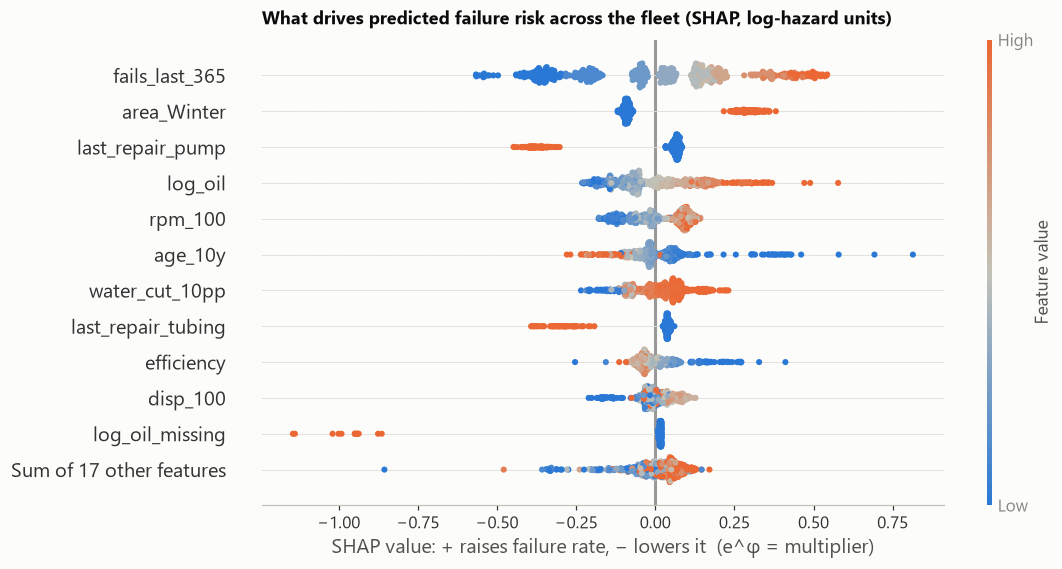

In [20]:
import shap
rng = np.random.default_rng(0)
Xf = X_all[fcols]
background = Xf.iloc[rng.choice(len(Xf), 200, replace=False)]
explainer = shap.Explainer(final.predict, shap.maskers.Independent(background, max_samples=200), feature_names=fcols)

glob_idx = rng.choice(len(Xf), 600, replace=False)
sv_glob = explainer(Xf.iloc[glob_idx], silent=True)               # fleet sample → global view

cmap = LinearSegmentedColormap.from_list("lohi", [BLUE, "#c3c2b7", ORANGE])
plt.figure()
shap.plots.beeswarm(sv_glob, max_display=12, show=False, color=cmap, plot_size=(10, 5.5))
plt.title("What drives predicted failure risk across the fleet (SHAP, log-hazard units)", loc="left", fontsize=11.5)
plt.gca().set_xlabel("SHAP value: + raises failure rate, − lowers it  (e^φ = multiplier)")
plt.show()

**Reason codes for the crew work list.** For each top-ranked well: its three biggest risk drivers and how much each multiplies its failure rate.

uwi,area,p_fail_90d,exp_cost_90d,why
102081203729W300,Cosine,77%,"$19,742",fails_last_365 = 9 (×1.36) · log_oil = 3.04 (×1.33) · age_10y = 0.183 (×1.05)
107151004225W300,Winter,97%,"$16,166",fails_last_365 = 10 (×1.69) · area_Winter = 1 (×1.43) · log_oil = 2.1 (×1.15)
102031004225W300,Winter,95%,"$15,851",fails_last_365 = 10 (×1.65) · area_Winter = 1 (×1.40) · log_oil = 2.08 (×1.15)
109101004225W300,Winter,97%,"$14,807",fails_last_365 = 10 (×1.68) · area_Winter = 1 (×1.43) · rpm_100 = 4.33 (×1.10)
102101004225W300,Winter,94%,"$14,767",fails_last_365 = 10 (×1.70) · area_Winter = 1 (×1.36) · rpm_100 = 3.57 (×1.11)
107101004225W300,Winter,87%,"$14,733",fails_last_365 = 10 (×1.63) · area_Winter = 1 (×1.43) · log_oil = 1.96 (×1.13)
104151004225W300,Winter,94%,"$14,582",fails_last_365 = 10 (×1.61) · area_Winter = 1 (×1.38) · rpm_100 = 2.75 (×1.10)
107063404125W300,Winter,89%,"$14,415",fails_last_365 = 9 (×1.54) · area_Winter = 1 (×1.37) · rpm_100 = 4.42 (×1.11)
104011604225W300,Winter,94%,"$14,156",fails_last_365 = 10 (×1.61) · area_Winter = 1 (×1.42) · age_10y = 0.158 (×1.07)
101110803520W300,Druid Main,61%,"$14,149",fails_last_365 = 8 (×1.39) · water_cut_10pp = 10 (×1.19) · age_10y = 0.0835 (×1.19)


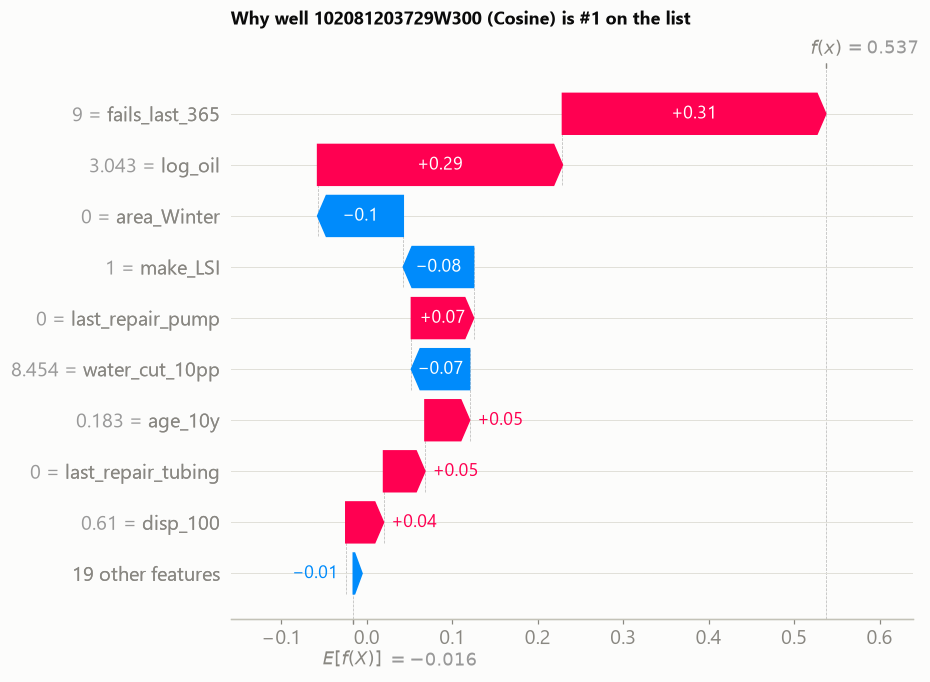

In [21]:
alert_X = X_all.loc[top.index, fcols]
sv_alert = explainer(alert_X, silent=True)

def reasons(row_sv, row_x, k=3):
    s = pd.Series(row_sv, index=fcols)
    is_dummy = s.index.str.startswith(("last_repair_", "area_", "make_"))
    keep = ~s.index.str.endswith("_missing") & ~(is_dummy & (row_x[fcols].to_numpy() == 0))
    s = s[keep].sort_values(ascending=False).head(k)              # skip "is NOT in area X" style reasons
    return " · ".join(f"{n} = {row_x[n]:.3g}  (×{np.exp(v):.2f})" for n, v in s.items())

top["why"] = [reasons(sv_alert.values[i], alert_X.iloc[i]) for i in range(len(top))]
display(top[["uwi", "area", "p_fail_90d", "exp_cost_90d", "why"]].head(10)
        .style.format({"p_fail_90d": "{:.0%}", "exp_cost_90d": "${:,.0f}"}).hide(axis="index"))

i = 0
plt.figure()
shap.plots.waterfall(sv_alert[i], max_display=10, show=False)
plt.title(f"Why well {top.uwi.iloc[i]} ({top.area.iloc[i]}) is #1 on the list", loc="left", fontsize=11.5)
plt.show()

## 9 · Cross-check: does the ML model agree with Cox?

Both models now speak in log-hazard. For each feature:

- **Cox** gives one global slope $\beta_j$: the change in log-hazard per unit of $x_j$.
- From SHAP we take the **average slope the boosted model learned**, by regressing $\phi_j$ on $x_j$ across the fleet sample.

If the two agree in sign and roughly in size, the ML model has learned the same physics as the transparent model and its extra accuracy can be trusted. Where they **disagree**, the cause could be non-linearity, an interaction, or a leakage or collinearity problem, so those features need a closer look before anyone acts on them.

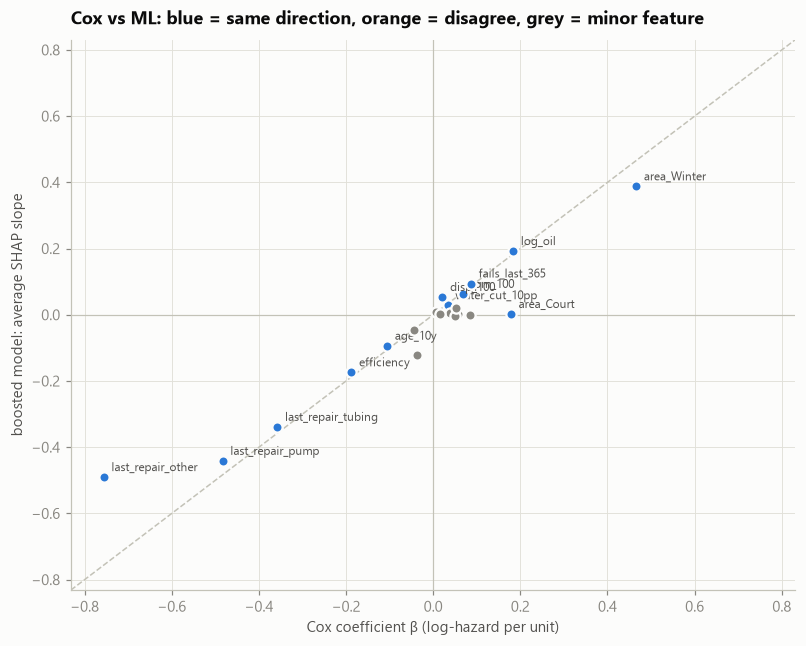

Sign agreement on the 12 important features: 100%


,Cox β,SHAP slope,Cox p,mean |SHAP|,agree
feature,,,,,
fails_last_365,+0.087,+0.094,1e-34,0.225,True
area_Winter,+0.466,+0.388,2e-14,0.149,True
last_repair_pump,-0.483,-0.442,1e-56,0.114,True
log_oil,+0.184,+0.192,1e-17,0.110,True
rpm_100,+0.067,+0.063,3e-06,0.078,True
age_10y,-0.106,-0.094,1e-06,0.073,True
water_cut_10pp,+0.033,+0.028,7e-07,0.067,True
last_repair_tubing,-0.357,-0.339,4e-19,0.063,True
efficiency,-0.188,-0.174,0.0003,0.048,True


In [22]:
xg = Xf.iloc[glob_idx]
rows = []
for j, name in enumerate(fcols):
    if name.endswith("_missing") or name not in cph.params_.index or xg[name].std() == 0:
        continue
    slope = np.polyfit(xg[name].to_numpy(), sv_glob.values[:, j], 1)[0]
    rows.append({"feature": name, "Cox β": cph.params_[name], "SHAP slope": slope,
                 "Cox p": cph.summary.loc[name, "p"], "mean |SHAP|": np.abs(sv_glob.values[:, j]).mean()})
cc = pd.DataFrame(rows).set_index("feature")
cc["agree"] = np.sign(cc["Cox β"]) == np.sign(cc["SHAP slope"])
imp_mask = (cc["Cox p"] < 0.05) | (cc["mean |SHAP|"] > cc["mean |SHAP|"].median())

fig, ax = plt.subplots(figsize=(8.5, 6.5))
lim = 1.1 * np.abs(cc[["Cox β", "SHAP slope"]].to_numpy()).max()
ax.plot([-lim, lim], [-lim, lim], color=AXIS, lw=1, ls="--")
ax.axhline(0, color=AXIS, lw=0.8); ax.axvline(0, color=AXIS, lw=0.8)
for name, r in cc.iterrows():
    c = (BLUE if r.agree else ORANGE) if imp_mask[name] else MUTED
    ax.scatter(r["Cox β"], r["SHAP slope"], color=c, s=45, zorder=3, edgecolor=SURFACE, lw=1.5)
    if imp_mask[name]:
        ax.annotate(name, (r["Cox β"], r["SHAP slope"]), xytext=(5, 4), textcoords="offset points",
                    fontsize=8, color=INK2)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.grid(axis="both", visible=True)
ax.set_xlabel("Cox coefficient β (log-hazard per unit)"); ax.set_ylabel("boosted model: average SHAP slope")
ax.set_title("Cox vs ML: blue = same direction, orange = disagree, grey = minor feature")
plt.show()
n_imp = imp_mask.sum()
print(f"Sign agreement on the {n_imp} important features: {cc.loc[imp_mask, 'agree'].mean():.0%}")
cc.loc[imp_mask].sort_values("mean |SHAP|", ascending=False).style.format(
    {"Cox β": "{:+.3f}", "SHAP slope": "{:+.3f}", "Cox p": "{:.1g}", "mean |SHAP|": "{:.3f}"})

## 10 · Summary

### Data finding that changes the analysis
The failure log (`production_failures`) only starts in **April 2025**. Failure-repair jobs from `well_jobs` work as a proxy for 2021–26: **~79% precision and ~95% recall** against the log where they overlap. This gives ~10k runs and ~9k failures instead of 18 months of data.

### What the survival analysis says (fleet level, lifelines)
- **Repairs don't last.** The median run after a repair is **~67 run-days**. Only 42% of runs reach day 90 and 13% reach a year. Another ~9% of failures happen within the first week after a repair.
- **The hazard falls with time: Weibull ρ ≈ 0.71 < 1.** Risk is highest right after a restart. That points to **repair quality and recurring root causes, not wear-out**, so scheduled preventive replacement would *not* help. Log-logistic fits best (AIC), the exponential (memoryless) fits worst.
- **Rod repairs are the weak spot.** After a rod repair the median run is **~52 days**, versus ~180 days after a pump or tubing repair (Cox: pump-repair runs have **0.62×** the hazard of rod-repair runs).
- **Risk factors (Cox HR, clustered SEs):** Winter area **1.6×**. Each repair in the past year **+9%**. **+7% per +100 RPM**. +3% per +10 pts water cut. Higher pump efficiency and older wells carry *lower* risk. In Kaplan–Meier terms, wells at 350+ RPM have a median run of ~44 days versus ~114 below 150 RPM.

### Prediction (scikit-survival, trained 2021–24, tested 2025–26)
| | Uno C | mean AUC(t) | IBS ↓ |
|---|---|---|---|
| history-only baseline | 0.63 | 0.69 | 0.139 |
| Cox | 0.67 | 0.74 | 0.125 |
| gradient-boosted Cox | **0.68** | **0.75** | **0.122** |

The ML models beat the baseline clearly, but beat Cox **only marginally**. Being honest: most of the signal is captured by a transparent model. Flagging the top 20% of runs reaches ~30% of 90-day failures, against 20% for random selection. That's useful for prioritising, but no crystal ball, because daily data with manual sensor readings limits what any model can see.

### Explainability and trust (SHAP + cross-check)
- SHAP reason codes turn each alert into "*9 repairs in the last year (×1.4), Winter area (×1.45), 430 RPM (×1.1)*".
- **The ML model and Cox agree in direction on 100% of the important features**, with similar sizes, so the boosted model has learned the same relationships as the interpretable one.

### Recommendations for Strathcona
1. **Use the risk-ranked work list** (§7) for proactive checks. About **1,000 active wells** carry about **300 expected failures and ≈ $4.6M of expected cost over the next 90 days** (at the stated price and cost assumptions). Repair cost dominates, because downtime per failure is short (~1.6 days).
2. **Do a root-cause review of rod repairs**, especially in **Winter** (rod string design, corrosion inhibition, centralizers). The early-failure pattern (ρ < 1) says the problem returns soon after a fix.
3. **Pilot lower pump speed** on high-RPM repeat-failure wells, to trade a little rate for longer run life. RPM is a risk factor the operator can actually change; treat it as a hypothesis and A/B test it.
4. **Phase 2:** high-frequency drive current and vibration data in a historian (e.g. Canary) with FFT features, starting on the top-risk wells this model identifies.

### Limitations
The proxy event includes some planned work (~21% false positives). Shut-ins may be *informative* censoring (poor wells get shut in). Covariates are fixed at restart (a time-varying Cox with RPM and torque trends is the next step). Torque, current and RPM are manual readings carried forward. The cost figures rest on stated assumptions (`PRICE_CAD_PER_BBL`, the mean repair cost).